# 01: Carbon Footprint Exploratory Analysis

Scope 1, 2 & 3 GHG emissions for **EcoNaija Manufacturing Ltd** (a fictional company, synthetic activity data), using the GHG Protocol activity-based method. Factors: **DESNZ 2026** (verified against the official workbook), a **derived Nigeria grid factor** (Scope 2 combustion-only, upstream and T&D in Scope 3 Cat 3; see `src/carbon/grid_factor.py`) and **US EPA** spend-based factors.

**Questions:**
1. What is the total footprint and how is it split across scopes?
2. Where are the emission hotspots?
3. Is the company on track for a 30% reduction vs the 2023 baseline?

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / 'src'))

import matplotlib.pyplot as plt
from carbon import load_activity, load_factors, calculate_emissions, summarise, reduction_vs_baseline

activity = load_activity()
factors = load_factors()
activity.head()

,period,site,activity_type,quantity,unit,year
0,2023-01-01,Lagos HQ,diesel,8334.62,litre,2023
1,2023-01-01,Lagos HQ,petrol,1286.25,litre,2023
2,2023-01-01,Lagos HQ,lpg,186.50,litre,2023
3,2023-01-01,Lagos HQ,refrigerant_r410a,1.38,kg,2023
4,2023-01-01,Lagos HQ,grid_electricity_ng,64256.48,kWh,2023


## 1. Data quality checks

In [2]:
print('Rows:', len(activity))
print('Periods:', activity['period'].min().date(), '→', activity['period'].max().date())
print('Missing values:\n', activity.isna().sum())
activity.groupby('activity_type')['unit'].unique()

Rows: 1116
Periods: 2023-01-01 → 2025-12-01
Missing values:
 period           0
site             0
activity_type    0
quantity         0
unit             0
year             0
dtype: int64


activity_type
business_travel_air_domestic    [passenger_km]
business_travel_air_longhaul    [passenger_km]
diesel                                 [litre]
employee_commute_car                      [km]
grid_electricity_ng                      [kWh]
lpg                                    [litre]
natural_gas                               [m3]
petrol                                 [litre]
purchased_goods_spend                    [USD]
refrigerant_r410a                         [kg]
waste_landfill                         [tonne]
Name: unit, dtype: object

## 2. Calculate emissions

In [3]:
emissions = calculate_emissions(activity, factors)
scope_year = summarise(emissions, ['year', 'scope']).pivot(index='year', columns='scope', values='tco2e')
scope_year.columns = [f'Scope {c}' for c in scope_year.columns]
scope_year['Total'] = scope_year.sum(axis=1)
scope_year.round(1)

,Scope 1,Scope 2,Scope 3,Total
year,,,,
2023,1242.7,990.5,2494.8,4727.9
2024,1186.5,942.5,2385.0,4514.0
2025,1143.1,915.2,2225.1,4283.5


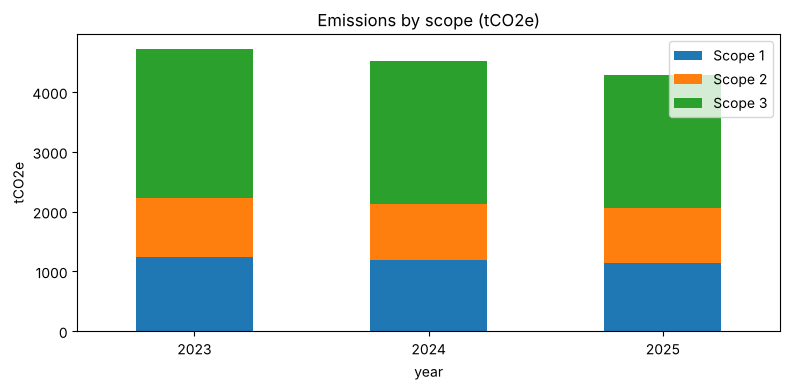

In [4]:
scope_year.drop(columns='Total').plot(kind='bar', stacked=True, figsize=(8, 4), title='Emissions by scope (tCO2e)')
plt.ylabel('tCO2e'); plt.xticks(rotation=0); plt.tight_layout(); plt.show()

## 3. Hotspots

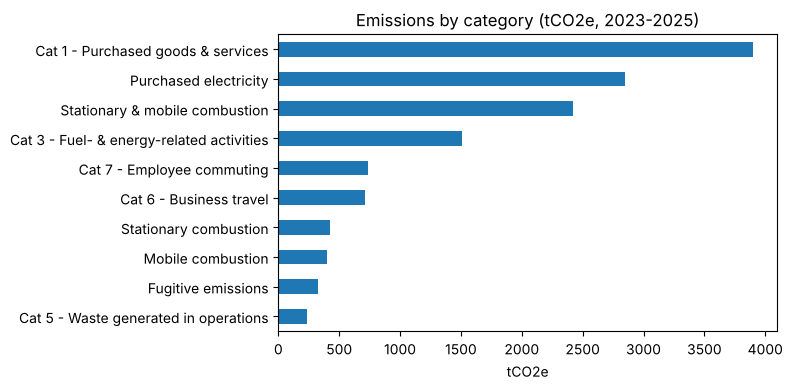

,category,tco2e,share_%
0,Cat 1 - Purchased goods & services,3901.763047,28.8
7,Purchased electricity,2848.138928,21.1
8,Stationary & mobile combustion,2420.109461,17.9
1,Cat 3 - Fuel- & energy-related activities,1512.031958,11.2
4,Cat 7 - Employee commuting,739.142218,5.5
3,Cat 6 - Business travel,715.117661,5.3
9,Stationary combustion,422.233005,3.1
6,Mobile combustion,400.111381,3.0
5,Fugitive emissions,329.908280,2.4
2,Cat 5 - Waste generated in operations,236.858799,1.8


In [5]:
hot = summarise(emissions, ['category']).sort_values('tco2e')
hot['share_%'] = (hot['tco2e'] / hot['tco2e'].sum() * 100).round(1)
hot.plot(x='category', y='tco2e', kind='barh', legend=False, figsize=(8, 4), title='Emissions by category (tCO2e, 2023-2025)')
plt.xlabel('tCO2e'); plt.ylabel(''); plt.tight_layout(); plt.show()
hot.sort_values('tco2e', ascending=False)

## 4. Progress vs 30% reduction target

In [6]:
progress = reduction_vs_baseline(emissions, baseline_year=2023)
progress.round(1)

,year,tco2e,pct_change_vs_baseline
0,2023,4727.9,0.0
1,2024,4514.0,-4.5
2,2025,4283.5,-9.4


## 5. Key findings

In [7]:
from IPython.display import Markdown
total = emissions.tco2e.sum(); s = summarise(emissions, ['scope']).set_index('scope').tco2e
top = hot.sort_values('tco2e', ascending=False).iloc[0]; chg = progress.set_index('year').pct_change_vs_baseline
Markdown(f'''
- **Total 2023-2025: {total:,.0f} tCO2e**: Scope 1 {s[1]/total:.0%}, Scope 2 {s[2]/total:.0%}, Scope 3 {s[3]/total:.0%}.
- **#1 hotspot: {top.category} ({top['share_%']:.0f}%)**. Spend-based, so it is also the most uncertain. Supplier data is the priority.
- **Scope 3 Cat 3** (upstream fuel supply and grid losses) is now reported separately, so Scope 2 is combustion-only, as the GHG Protocol requires.
- **Progress:** {chg[2025]:+.1f}% vs 2023, slightly ahead of a straight-line path to -30% by 2030 ({-30/7*2:.1f}% by 2025).

*Next:* scenario modelling of reduction levers (notebook 02).
''')


- **Total 2023-2025: 13,525 tCO2e**: Scope 1 26%, Scope 2 21%, Scope 3 53%.
- **#1 hotspot: Cat 1 - Purchased goods & services (29%)**. Spend-based, so it is also the most uncertain. Supplier data is the priority.
- **Scope 3 Cat 3** (upstream fuel supply and grid losses) is now reported separately, so Scope 2 is combustion-only, as the GHG Protocol requires.
- **Progress:** -9.4% vs 2023, slightly ahead of a straight-line path to -30% by 2030 (-8.6% by 2025).

*Next:* scenario modelling of reduction levers (notebook 02).
